In [1]:
import pandas as pd
test = pd.read_csv("Mall_Customers.csv")
test.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
train = pd.read_csv("Mall_Customers.csv")
train.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


In [6]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [7]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [8]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [12]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns
for column in kategorical_features:
   train[column] = train[column].fillna(train[column].mode()[0])

C:\Users\zacky raya novanda\AppData\Local\Temp\ipykernel_9528\3407389139.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kategorical_features = train[less].select_dtypes(include=['object']).columns


In [13]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [14]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

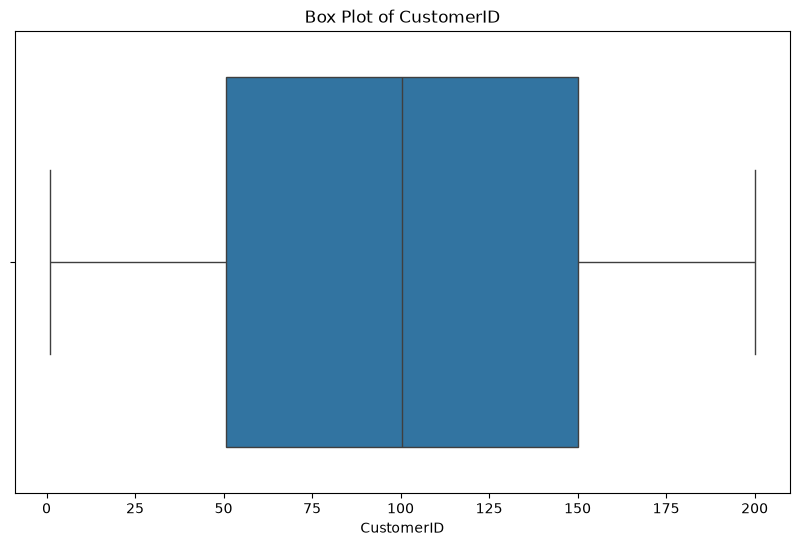

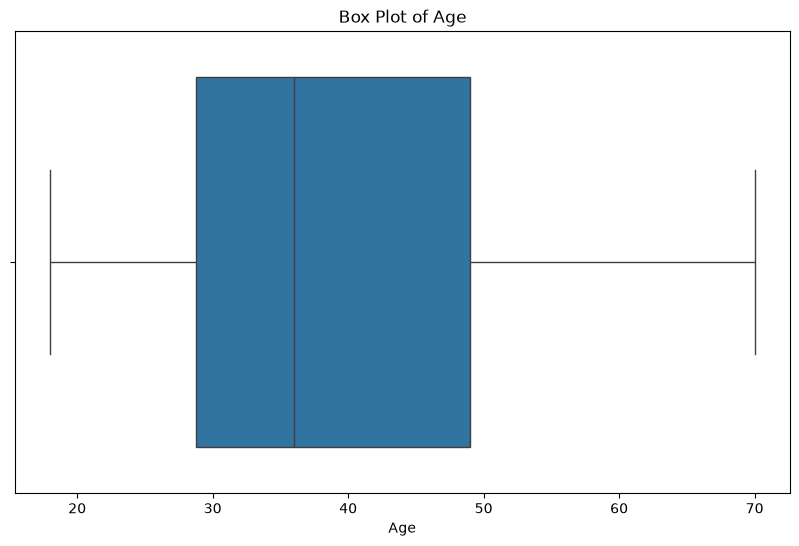

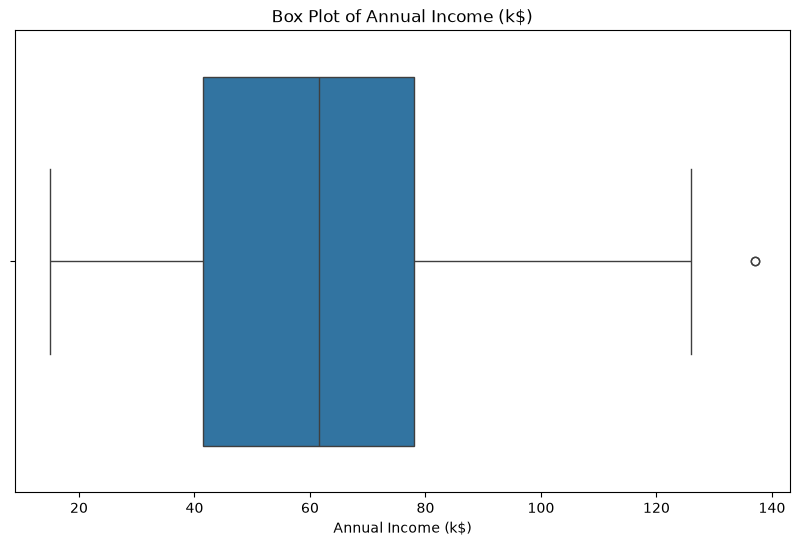

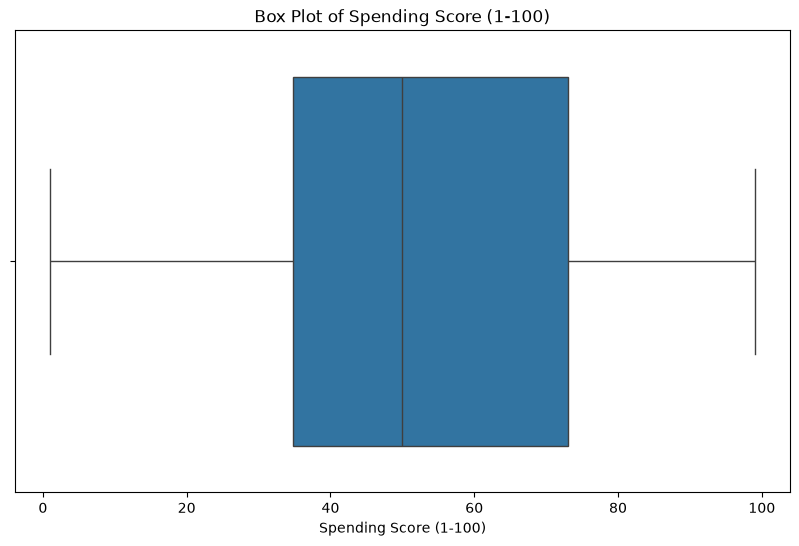

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
   plt.figure(figsize=(10, 6))
   sns.boxplot(x=df[feature])
   plt.title(f'Box Plot of {feature}')
   plt.show()

In [16]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [24]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 *IQR)) | (df[numeric_features] > (Q3 + 1.5* IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]
 
# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

C:\Users\zacky raya novanda\AppData\Local\Temp\ipykernel_9528\3264346486.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


In [25]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

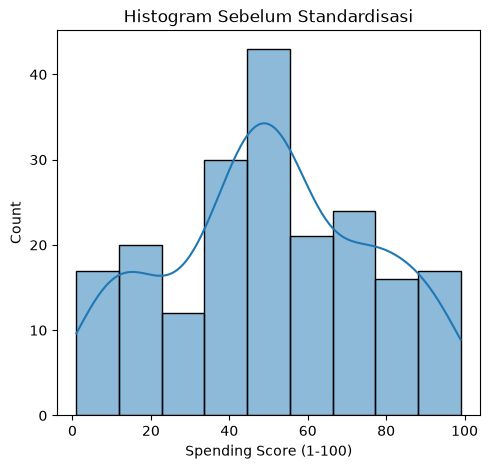

In [26]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

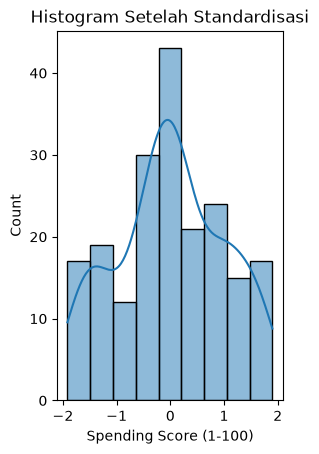

In [27]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [28]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
 
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [CustomerID, Age, Annual Income (k$), Spending Score (1-100), Gender]
Index: []


In [29]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
     CustomerID       Age  Annual Income (k$)  Spending Score (1-100)  Gender
0     -1.723325 -1.425414           -1.779171               -0.435989    Male
1     -1.705829 -1.282367           -1.779171                1.199413    Male
2     -1.688334 -1.353890           -1.739447               -1.720949  Female
3     -1.670838 -1.139319           -1.739447                1.043661  Female
4     -1.653342 -0.567131           -1.699723               -0.397051  Female
..          ...       ...                 ...                     ...     ...
193    1.653342 -0.066466            2.113819                1.588795  Female
194    1.670838  0.577246            2.391890               -1.331567  Female
195    1.688334 -0.281037            2.391890                1.121537  Female
196    1.705829  0.434198            2.630236               -0.864309  Female
197    1.723325 -0.495608            2.630236                0.926846    Male

[198 rows x 5 columns]


In [30]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\zacky raya novanda\AppData\Local\Temp\ipykernel_9528\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,Gender
0,Male
1,Male
2,Female
3,Female
4,Female
...,...
193,Female
194,Female
195,Female
196,Female


In [31]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male
0,-1.723325,-1.425414,-1.779171,-0.435989,False,True
1,-1.705829,-1.282367,-1.779171,1.199413,False,True
2,-1.688334,-1.353890,-1.739447,-1.720949,True,False
3,-1.670838,-1.139319,-1.739447,1.043661,True,False
4,-1.653342,-0.567131,-1.699723,-0.397051,True,False
...,...,...,...,...,...,...
193,1.653342,-0.066466,2.113819,1.588795,True,False
194,1.670838,0.577246,2.391890,-1.331567,True,False
195,1.688334,-0.281037,2.391890,1.121537,True,False
196,1.705829,0.434198,2.630236,-0.864309,True,False


In [32]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
   df_lencoder[col] = label_encoder.fit_transform(df[col])
 
# Menampilkan hasil
df_lencoder

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender
0,-1.723325,-1.425414,-1.779171,-0.435989,1
1,-1.705829,-1.282367,-1.779171,1.199413,1
2,-1.688334,-1.353890,-1.739447,-1.720949,0
3,-1.670838,-1.139319,-1.739447,1.043661,0
4,-1.653342,-0.567131,-1.699723,-0.397051,0
...,...,...,...,...,...
193,1.653342,-0.066466,2.113819,1.588795,0
194,1.670838,0.577246,2.391890,-1.331567,0
195,1.688334,-0.281037,2.391890,1.121537,0
196,1.705829,0.434198,2.630236,-0.864309,0


In [9]:
import pandas as pd
df_lencoder = pd.read_csv("Mall_Customers.csv")
df_lencoder.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [11]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
 
missing_data = pd.DataFrame({
   'Missing Values': missing_values,
   'Percentage': missing_percentage
 }).sort_values(by='Missing Values', ascending=False)
 
missing_data[missing_data['Missing Values'] > 0] # Menampilkan kolom dengan missing values

,Missing Values,Percentage


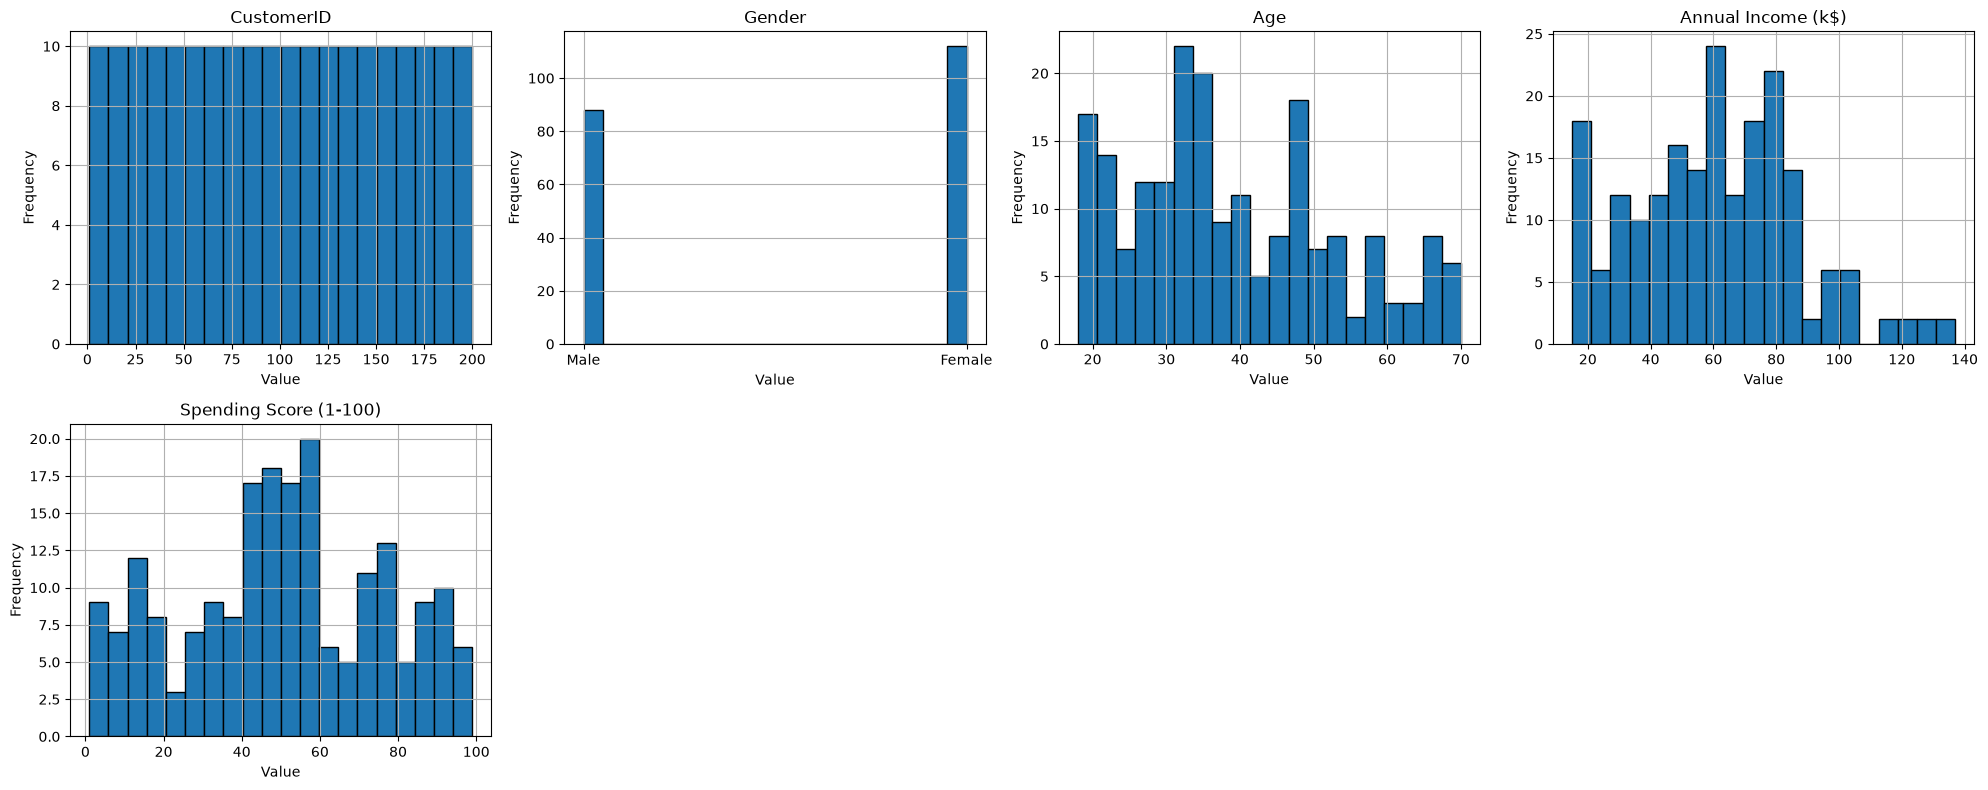

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]
 
# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris
 
# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
 
# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()
 
# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
   df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
   axes[i].set_title(column)
   axes[i].set_xlabel('Value')
   axes[i].set_ylabel('Frequency')
 
# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
   fig.delaxes(axes[j])
 
# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()


['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


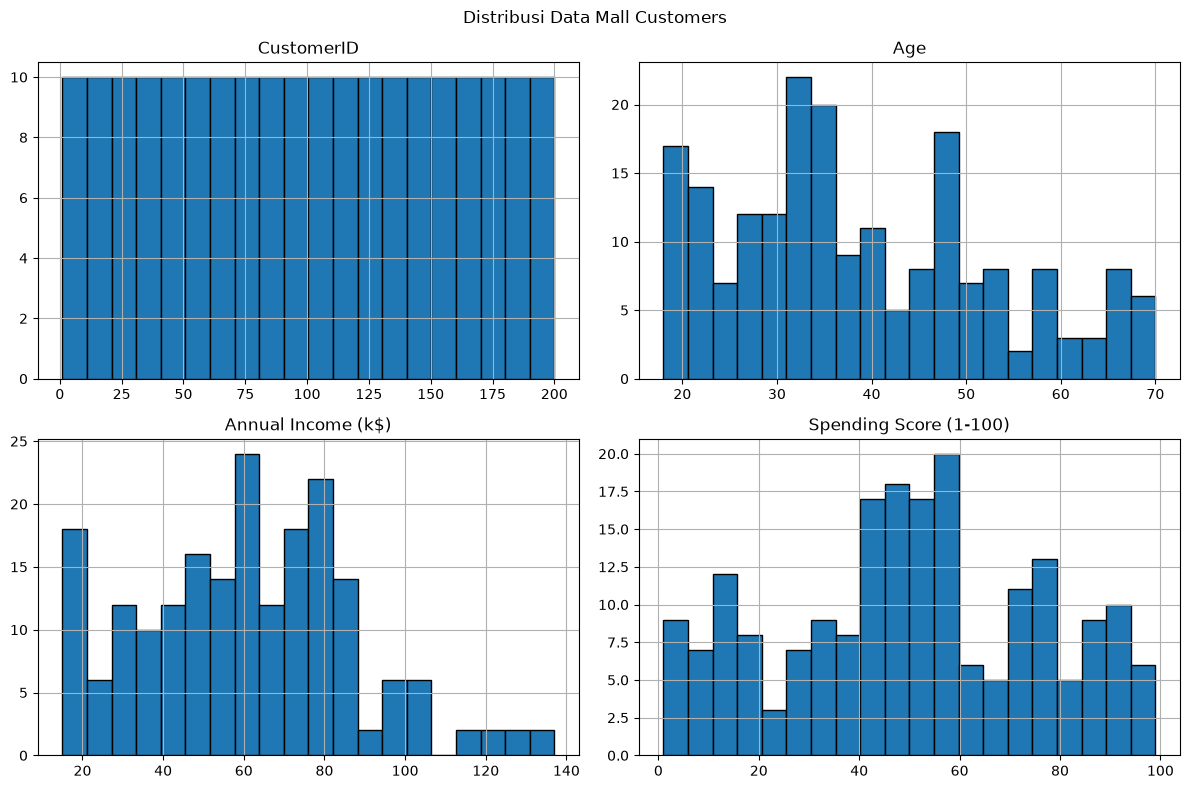

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Membaca dataset Mall Customers
df_lencoder = pd.read_csv("Mall_Customers.csv")

# Menampilkan nama kolom
print(df_lencoder.columns.tolist())

# Memilih kolom numerik
df_numerik = df_lencoder.select_dtypes(include="number")

# Membuat histogram
df_numerik.hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribusi Data Mall Customers")
plt.tight_layout()
plt.show()

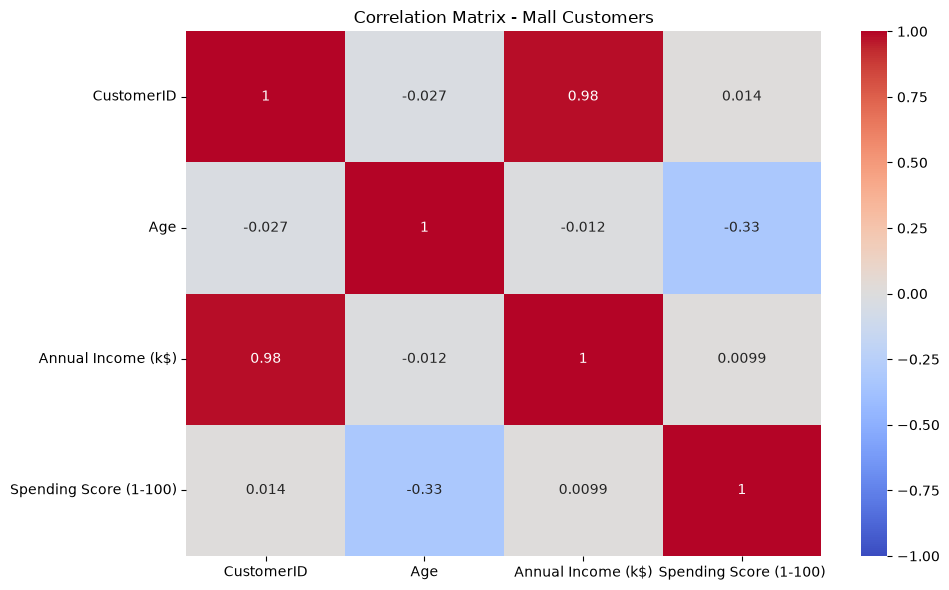

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Memilih kolom numerik saja
df_numerik = df_lencoder.select_dtypes(include="number")

# Menghitung korelasi antarvariabel numerik
correlation_matrix = df_numerik.corr()

# Membuat heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix - Mall Customers")
plt.tight_layout()
plt.show()

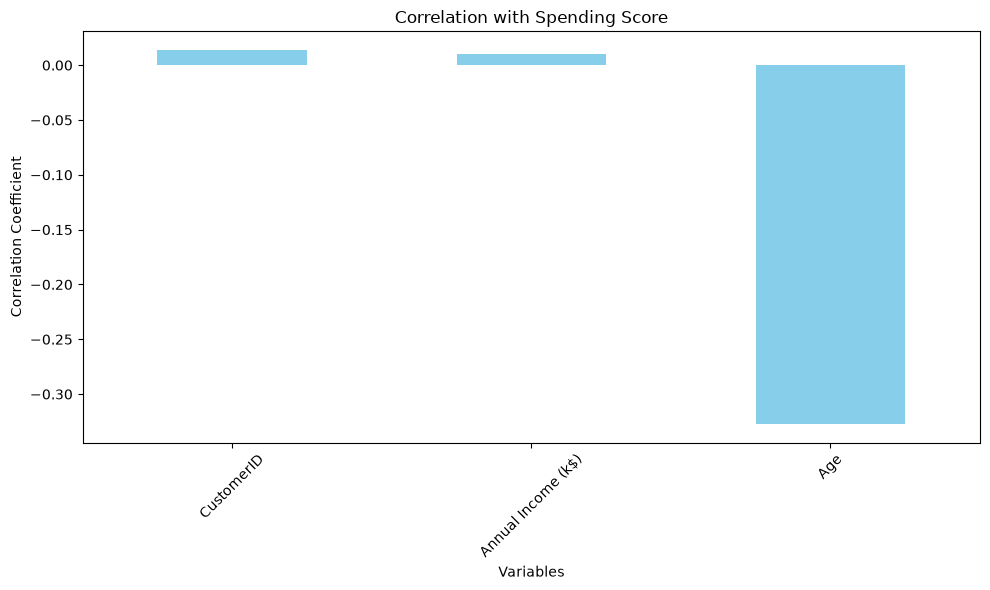

In [23]:
import matplotlib.pyplot as plt

# Mengambil kolom numerik
df_numerik = df_lencoder.select_dtypes(include="number")

# Menghitung korelasi antarvariabel numerik
correlation_matrix = df_numerik.corr()

# Mengambil korelasi terhadap Spending Score
target_corr = correlation_matrix["Spending Score (1-100)"]

# Mengurutkan berdasarkan nilai korelasi
target_corr_sorted = target_corr.drop(
    "Spending Score (1-100)"
).sort_values(ascending=False)

# Membuat grafik
plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind="bar", color="skyblue")

plt.title("Correlation with Spending Score")
plt.xlabel("Variables")
plt.ylabel("Correlation Coefficient")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
import sklearn

In [29]:
# Memilih fitur untuk customer segmentation
X = df_lencoder[
    ['Annual Income (k$)', 'Spending Score (1-100)']
]

# Menampilkan 5 data pertama
print(X.head())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Memilih fitur pendapatan dan skor belanja
X = df_lencoder[
    ['Annual Income (k$)', 'Spending Score (1-100)']
]

# Normalisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Mengelompokkan pelanggan menjadi 5 cluster
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_lencoder['Cluster'] = kmeans.fit_predict(X_scaled)

# Menampilkan hasil
print(df_lencoder[['Annual Income (k$)',
                   'Spending Score (1-100)',
                   'Cluster']].head())

   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4


In [33]:
# Menghitung jumlah data
print("Jumlah seluruh data:", len(X))

# Menghitung jumlah data pelanggan
print("Jumlah data pelanggan:", len(df_lencoder))

# Menghitung jumlah data setiap cluster
print("\nJumlah pelanggan setiap cluster:")
print(df_lencoder["Cluster"].value_counts().sort_index())

Jumlah seluruh data: 200
Jumlah data pelanggan: 200

Jumlah pelanggan setiap cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [39]:
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Lars
from sklearn.model_selection import train_test_split

# 1. Load dataset Mall_Customers.csv
df = pd.read_csv('Mall_Customers.csv')

# 2. Tentukan fitur (X) dan target (y)
X = df[['Age', 'Annual Income (k$)']]
y = df['Spending Score (1-100)']

# 3. Bagi data (menggunakan x_train huruf kecil sesuai kode Anda)
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================
# KODE PELATIHAN MODEL (SUDAH DIPERBAIKI)
# ==========================================

# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model

lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression

LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor

GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

print('Semua model berhasil dilatih tanpa error!')

Semua model berhasil dilatih tanpa error!


In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
 
# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)
 
# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
   'MAE': [mae_lars],
   'MSE': [mse_lars],
   'R2': [r2_lars]
 }
 
# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results



,MAE,MSE,R2
Lars,17.542496,482.884786,0.020994


In [41]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)
 
# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results


,MAE,MSE,R2
Lars,17.542496,482.884786,0.020994
Linear Regression,18.228973,483.556822,0.019632


In [42]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)
 
# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,17.542496,482.884786,0.020994
Linear Regression,18.228973,483.556822,0.019632
GradientBoostingRegressor,11.115055,368.698665,0.252496


In [43]:
import joblib
 
# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

['gbr_model.joblib']

In [44]:
import pickle
 
# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
   pickle.dump(GBR, file)
